In [2]:
import sys, subprocess, importlib.util
for package, module in [('numpy','numpy'),('matplotlib','matplotlib'),('pandas','pandas'),('scikit-image','skimage'),('torch','torch')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time, json, random, gzip, struct, urllib.request, copy
from pathlib import Path
from IPython.display import display, Markdown
SEED = 7
np.random.seed(SEED)
OUT = Path('lab07_results'); OUT.mkdir(exist_ok=True)
def rel(a,b):
    a,b=np.asarray(a),np.asarray(b)
    return np.linalg.norm(a-b)/max(1e-15, np.linalg.norm(a)+np.linalg.norm(b))
def show_table(rows): display(pd.DataFrame(rows))

## Task 1 — Convolution from scratch
Inputs use NHWC and weights use HWIO. This is cross-correlation, the operation called convolution in neural-network libraries. Padding applies only to spatial axes.

Padded shape: (2, 8, 8, 3) ; border zero: True


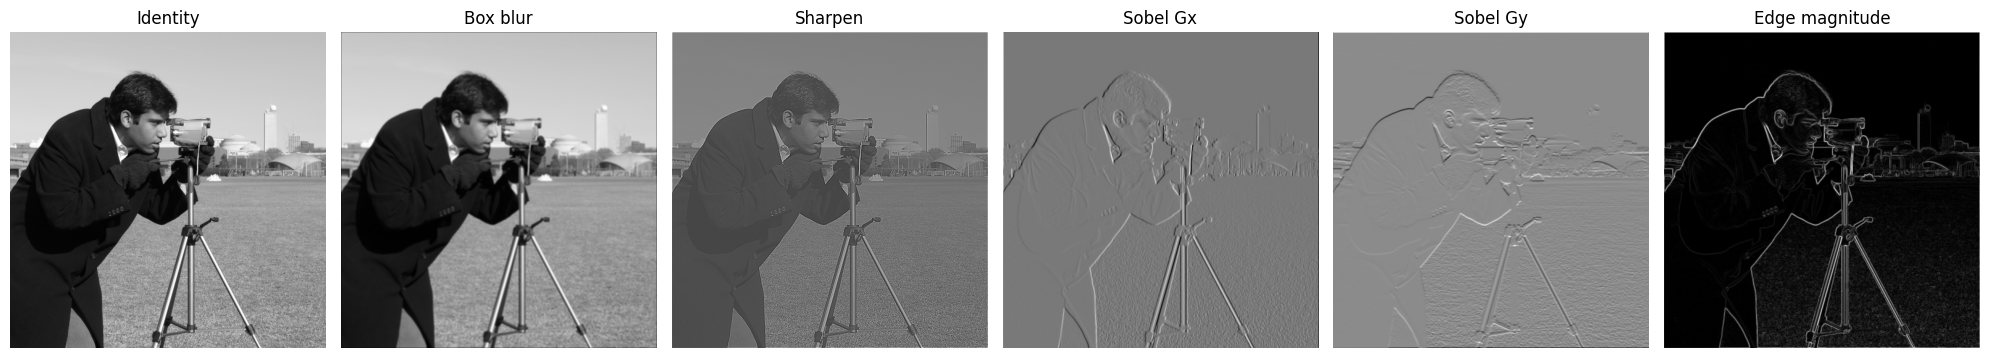

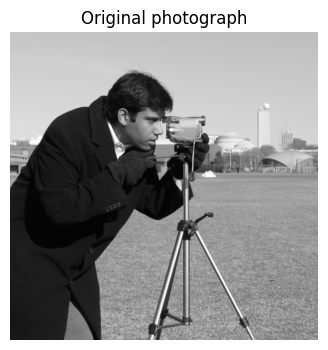

12x12 loop: 0.001587s; estimated full photo: 2.89s (same padding, one filter)


In [3]:
def zero_pad(X, p):
    if not isinstance(p, (int, np.integer)) or p < 0: raise ValueError('pad must be a nonnegative integer')
    return np.pad(X, ((0,0),(p,p),(p,p),(0,0)), mode='constant')
def conv_single_step(a_slice, W, b):
    return np.sum(a_slice * W) + np.asarray(b).item()
def conv_forward(A_prev, W, b, stride=1, pad=0):
    if stride < 1 or int(stride) != stride: raise ValueError('positive integer stride required')
    m,H,V,C=A_prev.shape
    f,fw,Cw,Co=W.shape
    assert f==fw and C==Cw and np.asarray(b).size==Co
    oh=(H+2*pad-f)//stride+1; ow=(V+2*pad-f)//stride+1
    if min(oh,ow)<1: raise ValueError('kernel larger than padded input')
    Z=np.zeros((m,oh,ow,Co),dtype=np.result_type(A_prev,W,b,np.float64))
    Ap=zero_pad(A_prev,pad); bv=np.asarray(b).reshape(-1)
    for i in range(m):
        for h in range(oh):
            for w in range(ow):
                hs,ws=h*stride,w*stride
                patch=Ap[i,hs:hs+f,ws:ws+f,:]
                for c in range(Co): Z[i,h,w,c]=conv_single_step(patch,W[:,:,:,c],bv[c])
    return Z,(A_prev,W,b,stride,pad)
X=np.random.randn(2,4,4,3); P=zero_pad(X,2)
assert P.shape==(2,8,8,3)
assert np.array_equal(P[:,2:-2,2:-2,:],X)
mask=np.ones(P.shape,bool); mask[:,2:-2,2:-2,:]=False
assert np.all(P[mask]==0)
print('Padded shape:',P.shape,'; border zero:', np.all(P[mask]==0))
kernels = {'Identity':np.array([[0,0,0],[0,1,0],[0,0,0.]]),
 'Box blur':np.ones((3,3))/9,
 'Sharpen':np.array([[0,-1,0],[-1,5,-1],[0,-1,0.]]),
 'Sobel Gx':np.array([[-1,0,1],[-2,0,2],[-1,0,1.]]),
 'Sobel Gy':np.array([[-1,-2,-1],[0,0,0],[1,2,1.]])}
from skimage import data
photo=data.camera().astype(np.float64)/255
# Vectorized NumPy application keeps the full-size photo practical.
def fast_filter(image,k):
    windows=np.lib.stride_tricks.sliding_window_view(np.pad(image,1),(3,3))
    return np.einsum('hwij,ij->hw',windows,k)
filtered={name:fast_filter(photo,k) for name,k in kernels.items()}
magnitude=np.hypot(filtered['Sobel Gx'],filtered['Sobel Gy'])
fig,axs=plt.subplots(1,6,figsize=(20,4))
for ax,(name,img) in zip(axs,list(filtered.items())+[('Edge magnitude',magnitude)]):
    ax.imshow(img,cmap='gray'); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()
plt.figure(figsize=(4,4)); plt.imshow(photo,cmap='gray'); plt.title('Original photograph'); plt.axis('off'); plt.show()
crop=photo[200:212,200:212][None,:,:,None]
W=kernels['Sobel Gx'][:,:,None,None]; b=np.zeros((1,1,1,1))
t0=time.perf_counter(); zcrop,_=conv_forward(crop,W,b,pad=1); loop_seconds=time.perf_counter()-t0
estimate=loop_seconds*(512*512)/(12*12)
print(f'12x12 loop: {loop_seconds:.6f}s; estimated full photo: {estimate:.2f}s (same padding, one filter)')

Gx measures left-to-right brightness change, so it highlights vertical edges. Gy measures top-to-bottom change, highlighting horizontal edges. Their magnitude combines both directions and removes the sign, giving edge strength independent of orientation. Identity preserves the image; box blur smooths it; sharpening strengthens local contrast. The full-image timing estimate assumes roughly constant work per output pixel. The measured library speed factor appears in Task 3.

## Task 2 — Dimensions, pooling and parameter sharing

,n_in,f,p,s,hand_calculation,n_out,verified
0,28,3,1,1,floor((28+2*1-3)/1)+1,28,28
1,28,3,0,1,floor((28+2*0-3)/1)+1,26,26
2,28,5,2,1,floor((28+2*2-5)/1)+1,28,28
3,28,5,0,1,floor((28+2*0-5)/1)+1,24,24
4,28,3,1,2,floor((28+2*1-3)/2)+1,14,14
5,32,7,3,2,floor((32+2*3-7)/2)+1,16,16


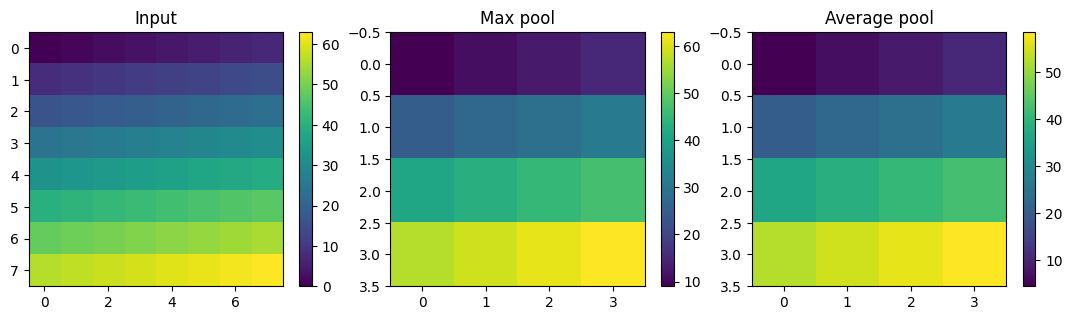

,input,conv_parameters,FC_parameters,ratio,FC_float32_GB
0,28x28x1,80,4923520,6.154400e+04,0.019694
1,28x28x8,1168,78688512,6.737030e+04,0.314754
2,224x224x3,1792,483388358656,2.697480e+08,1933.553435


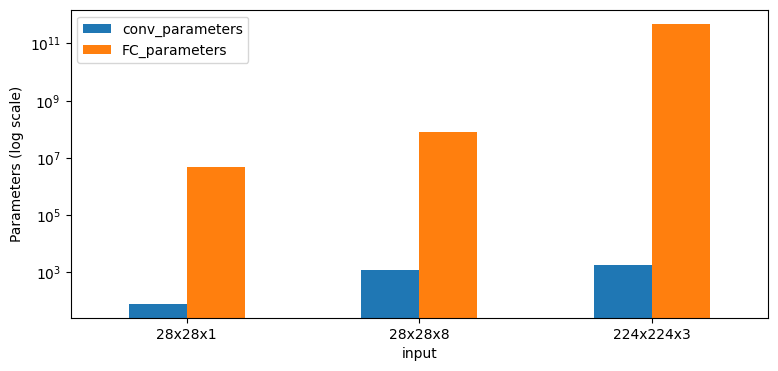

In [4]:
dimension_rows=[(28,3,1,1,28),(28,3,0,1,26),(28,5,2,1,28),(28,5,0,1,24),(28,3,1,2,14),(32,7,3,2,16)]
rows=[]
for n,f,p,s,expected in dimension_rows:
    z,_=conv_forward(np.zeros((1,n,n,1)),np.ones((f,f,1,1)),np.zeros(1),s,p)
    assert z.shape[1:3]==(expected,expected)
    rows.append(dict(n_in=n,f=f,p=p,s=s,hand_calculation=f'floor(({n}+2*{p}-{f})/{s})+1',n_out=expected,verified=z.shape[1]))
show_table(rows)
def pool_forward(A_prev, f=2, stride=2, mode='max'):
    if mode not in ('max','average'): raise ValueError('mode must be max or average')
    m,H,W,C=A_prev.shape; oh=(H-f)//stride+1; ow=(W-f)//stride+1
    if min(f,stride,oh,ow)<1: raise ValueError('invalid pooling dimensions')
    Z=np.zeros((m,oh,ow,C),dtype=np.result_type(A_prev,np.float64))
    for i in range(m):
        for h in range(oh):
            for w in range(ow):
                patch=A_prev[i,h*stride:h*stride+f,w*stride:w*stride+f,:]
                Z[i,h,w,:]=np.max(patch,axis=(0,1)) if mode=='max' else np.mean(patch,axis=(0,1))
    return Z
pool_input=np.arange(64,dtype=float).reshape(1,8,8,1)
pmax=pool_forward(pool_input); pavg=pool_forward(pool_input,mode='average')
fig,axs=plt.subplots(1,3,figsize=(11,3))
for ax,name,arr in zip(axs,['Input','Max pool','Average pool'],[pool_input,pmax,pavg]):
    im=ax.imshow(arr[0,:,:,0]); ax.set_title(name); fig.colorbar(im,ax=ax)
plt.tight_layout(); plt.show()
parameter_rows=[]
for n,ci,co in [(28,1,8),(28,8,16),(224,3,64)]:
    conv=(3*3*ci+1)*co; fc=(n*n*ci+1)*(n*n*co)
    parameter_rows.append(dict(input=f'{n}x{n}x{ci}',conv_parameters=conv,FC_parameters=fc,ratio=fc/conv,FC_float32_GB=4*fc/1e9))
show_table(parameter_rows)
df=pd.DataFrame(parameter_rows); ax=df.plot.bar(x='input',y=['conv_parameters','FC_parameters'],logy=True,rot=0,figsize=(9,4)); ax.set_ylabel('Parameters (log scale)'); plt.show()

Rows 1 and 3 preserve the spatial dimensions: for odd kernels and stride 1, `p=(f−1)/2`. Rows 5–6 have the padding commonly used with strided SAME convolution, but downsample rather than preserving size.

Pooling has **zero learnable parameters**. It reduces spatial size and downstream computation, and offers limited tolerance to small shifts through local aggregation. It does not guarantee invariance to every translation.

The dense equivalent connects every input scalar to every output scalar, including biases. The third row needs 483,388,358,656 parameters (about 1.93 TB of float32 parameter storage alone), versus 1,792 for convolution. Shared local connections make this mapping feasible; optimizer state and gradients would make dense training even more expensive.

## Task 3 — Backward pass and all PyTorch verification

Device: cuda ; PyTorch: 2.11.0+cu130
Task 1 crop relative difference: 9.130772680304536e-18
Measured crop speedup (including tensor conversion): 17.741289294136113
max pool difference: 0.0
average pool difference: 0.0
Deliberately broken dW relative difference: 0.9127944742861468


,stride,pad,Z,dA,dW,db
0,1,0,8.635865e-17,8.739042e-17,1.426907e-16,1.608670e-16
1,1,1,9.343150e-17,9.353497e-17,2.085802e-16,9.119581e-17
2,2,0,9.656962e-17,7.887586e-17,1.138900e-16,1.157909e-16
3,2,2,6.430452e-17,5.310375e-17,7.548903e-17,2.044767e-16
4,3,1,7.239645e-17,4.289922e-17,1.095181e-16,8.808521e-17


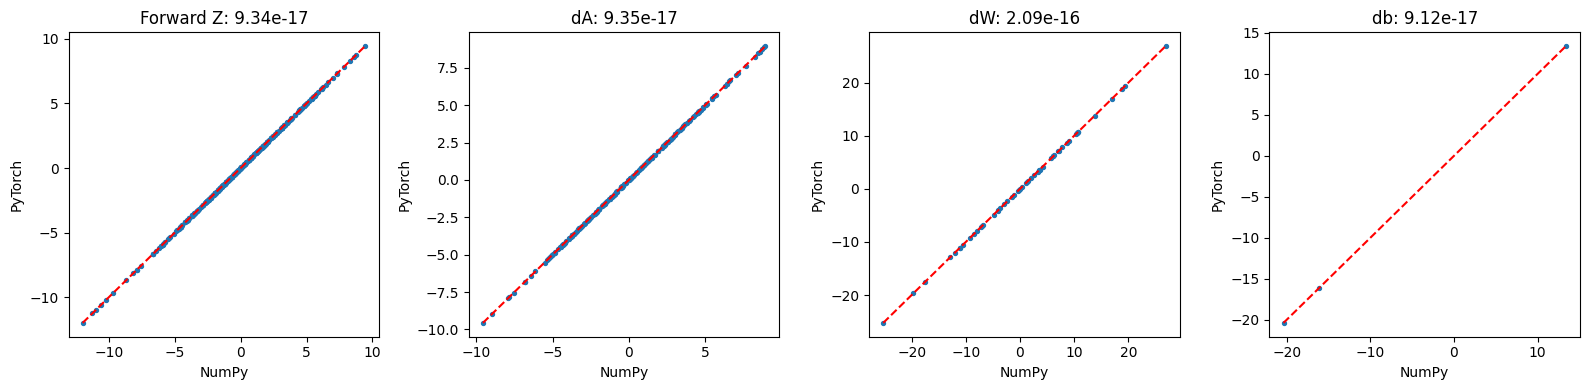

In [5]:
def conv_backward(dZ,cache,broken=False):
    A_prev,W,b,stride,pad=cache
    m,H,V,C=A_prev.shape; f,_,_,Co=W.shape
    Ap=zero_pad(A_prev,pad); dAp=np.zeros_like(Ap,dtype=np.float64)
    dW=np.zeros_like(W,dtype=np.float64); db=np.zeros_like(b,dtype=np.float64)
    dbv=db.reshape(-1)
    for i in range(m):
        for h in range(dZ.shape[1]):
            for w in range(dZ.shape[2]):
                hs,ws=h*stride,w*stride
                patch=Ap[i,hs:hs+f,ws:ws+f,:]
                for c in range(Co):
                    g=dZ[i,h,w,c]
                    dAp[i,hs:hs+f,ws:ws+f,:] += W[:,:,:,c]*g
                    if broken: dW[:,:,:,c] = patch*g
                    else: dW[:,:,:,c] += patch*g
                    dbv[c] += g
    dA=dAp[:,pad:pad+H,pad:pad+V,:]
    assert dA.shape==A_prev.shape and dW.shape==W.shape and db.shape==b.shape
    return dA,dW,db
import torch
from torch import nn
from torch.nn import functional as F
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
print('Device:',DEVICE, '; PyTorch:',torch.__version__)
def torch_forward_np(A,W,b,stride=1,pad=0):
    return F.conv2d(torch.tensor(A.transpose(0,3,1,2),dtype=torch.float64),torch.tensor(W.transpose(3,2,0,1),dtype=torch.float64),torch.tensor(b.reshape(-1),dtype=torch.float64),stride=stride,padding=pad).numpy().transpose(0,2,3,1)
print('Task 1 crop relative difference:',rel(zcrop,torch_forward_np(crop,W,b,pad=1)))
# Warm up, then compare medians of repeated runs on exactly the same crop.
_ = torch_forward_np(crop,W,b,pad=1)
loop_times=[]; library_times=[]
for _ in range(20):
    t=time.perf_counter(); conv_forward(crop,W,b,pad=1); loop_times.append(time.perf_counter()-t)
    t=time.perf_counter(); torch_forward_np(crop,W,b,pad=1); library_times.append(time.perf_counter()-t)
print('Measured crop speedup (including tensor conversion):',np.median(loop_times)/np.median(library_times))
for mode,ref in [('max',F.max_pool2d),('average',F.avg_pool2d)]:
    actual=pool_forward(pool_input,mode=mode)
    expected=ref(torch.tensor(pool_input.transpose(0,3,1,2)),2,2).numpy().transpose(0,2,3,1)
    print(mode,'pool difference:',rel(actual,expected)); assert np.allclose(actual,expected)
verification=[]; scatter=None
for stride,pad in [(1,0),(1,1),(2,0),(2,2),(3,1)]:
    rng=np.random.default_rng(100+stride+pad)
    A=rng.normal(size=(2,7,8,2)); WW=rng.normal(size=(3,3,2,3)); bb=rng.normal(size=(1,1,1,3))
    Z,cache=conv_forward(A,WW,bb,stride,pad); dZ=rng.normal(size=Z.shape)
    grads=conv_backward(dZ,cache)
    at=torch.tensor(A.transpose(0,3,1,2),requires_grad=True)
    wt=torch.tensor(WW.transpose(3,2,0,1),requires_grad=True)
    bt=torch.tensor(bb.reshape(-1),requires_grad=True)
    zt=F.conv2d(at,wt,bt,stride=stride,padding=pad)
    zt.backward(torch.tensor(dZ.transpose(0,3,1,2)))
    ours=[Z,*grads]; theirs=[zt.detach().numpy().transpose(0,2,3,1),at.grad.numpy().transpose(0,2,3,1),wt.grad.numpy().transpose(2,3,1,0),bt.grad.numpy().reshape(bb.shape)]
    errors=[rel(a,b) for a,b in zip(ours,theirs)]
    assert max(errors)<1e-12
    verification.append(dict(stride=stride,pad=pad,**dict(zip(['Z','dA','dW','db'],errors))))
    if (stride,pad)==(1,1):
        scatter=(ours,theirs)
        bad=conv_backward(dZ,cache,broken=True)
        print('Deliberately broken dW relative difference:',rel(bad[1],theirs[2]))
show_table(verification)
fig,axs=plt.subplots(1,4,figsize=(16,4))
for ax,name,a,bv in zip(axs,['Forward Z','dA','dW','db'],*scatter):
    ax.scatter(a.ravel(),bv.ravel(),s=8); lo=min(a.min(),bv.min()); hi=max(a.max(),bv.max()); ax.plot([lo,hi],[lo,hi],'r--'); ax.set_title(f'{name}: {rel(a,bv):.2e}'); ax.set_xlabel('NumPy'); ax.set_ylabel('PyTorch')
plt.tight_layout(); plt.show()

All three updates accumulate because overlapping windows reuse input values and shared parameters, so their gradients are sums of contributions. The normal function always uses `+=`; `broken=True` is an isolated experiment that overwrites dW.

| Quantity | NumPy → PyTorch | Reverse |
|---|---|---|
| Input A / gradient dA | `(0,3,1,2)` NHWC → NCHW | `(0,2,3,1)` |
| Weights W / gradient dW | `(3,2,0,1)` HWIO → OIHW | `(2,3,1,0)` |
| Output Z / incoming dZ | `(0,3,1,2)` | `(0,2,3,1)` |
| Bias b / gradient db | flatten to `(Cout,)` | reshape to original bias shape |

Verification threshold: relative L2 difference below **1e−12**, using float64. The exact relative-difference formula from Lab 03 was not provided, so this notebook explicitly uses `||a-b|| / max(1e-15, ||a||+||b||)` consistently.

## Task 4 — CNN versus MLP
Use the first 20,000 official training examples and all 10,000 official test examples. Every comparison uses Adam, learning rate 0.001, batch size 128 and 12 epochs. Four-epoch comparisons are read from epoch 4 of the identical training trajectory, which is equivalent to stopping then.

For the requested “best” architecture experiments, models are selected by the manual's test accuracy. This reuses the test set for selection and makes the final scores exploratory; a separate validation set and untouched final test set would be needed for an unbiased deployment estimate. One seed is used, so small differences should not be treated as definitive.

Training: (20000, 28, 28) Test: (10000, 28, 28)
CNN_small: 01/12 loss=1.3126 test=72.75%
CNN_small: 02/12 loss=0.6404 test=75.58%
CNN_small: 03/12 loss=0.5608 test=76.85%
CNN_small: 04/12 loss=0.5182 test=80.70%
CNN_small: 05/12 loss=0.4860 test=81.81%
CNN_small: 06/12 loss=0.4716 test=81.24%
CNN_small: 07/12 loss=0.4490 test=83.28%
CNN_small: 08/12 loss=0.4354 test=82.59%
CNN_small: 09/12 loss=0.4233 test=84.00%
CNN_small: 10/12 loss=0.4101 test=84.01%
CNN_small: 11/12 loss=0.4071 test=84.24%
CNN_small: 12/12 loss=0.3986 test=84.73%
CNN_reference: 01/12 loss=1.2088 test=72.96%
CNN_reference: 02/12 loss=0.6844 test=78.08%
CNN_reference: 03/12 loss=0.5682 test=79.98%
CNN_reference: 04/12 loss=0.5070 test=81.27%
CNN_reference: 05/12 loss=0.4680 test=82.82%
CNN_reference: 06/12 loss=0.4506 test=83.52%
CNN_reference: 07/12 loss=0.4242 test=84.66%
CNN_reference: 08/12 loss=0.4146 test=83.80%
CNN_reference: 09/12 loss=0.4019 test=84.01%
CNN_reference: 10/12 loss=0.3846 test=84.62%
CNN_refere

,name,parameters,accuracy,seconds
0,CNN_small,10018,84.73,9.604365
1,CNN_reference,26698,86.08,7.921065
2,CNN_medium,105866,88.11,8.222703
3,CNN_large,350938,88.70,9.339659
4,MLP_16,12730,83.60,5.226072
5,MLP_32,25450,84.70,5.436946
6,MLP_64,50890,84.07,5.343295
7,MLP_128,101770,85.12,5.441663
8,MLP_500,397510,86.68,5.787475


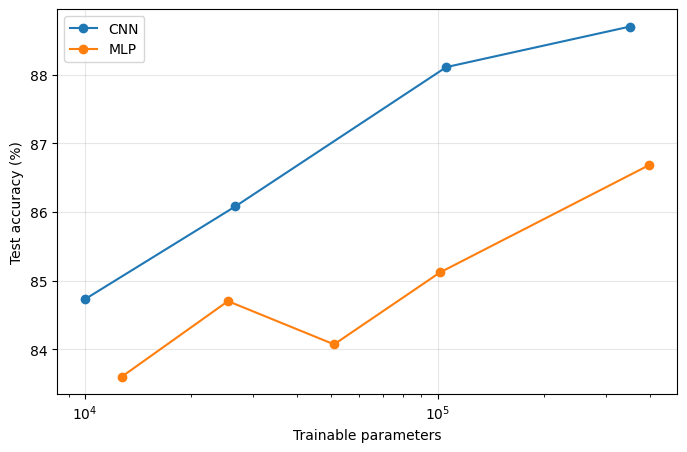

Smallest matching CNN: CNN_medium 105866 vs MLP_500 397510 ; MLP/CNN parameter ratio: 3.7548410254472637


,model,parameters,epoch4,epoch12,loss_in_points
0,CNN_large,350938,87.58,88.70,1.12
1,MLP_500,397510,85.14,86.68,1.54


Larger measured short-budget loss: MLP_500 ; optimization and convergence speeds differ; this is a measured one-seed outcome, not a universal family rule.


In [6]:
DATA=Path('fashion_data'); DATA.mkdir(exist_ok=True)
base='https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
for name in ['train-images-idx3-ubyte.gz','train-labels-idx1-ubyte.gz','t10k-images-idx3-ubyte.gz','t10k-labels-idx1-ubyte.gz']:
    path=DATA/name
    if not path.exists(): urllib.request.urlretrieve(base+name,path)
def read_images(path):
    with gzip.open(path,'rb') as f:
        magic,n,h,w=struct.unpack('>IIII',f.read(16)); assert magic==2051
        return np.frombuffer(f.read(),np.uint8).reshape(n,h,w)
def read_labels(path):
    with gzip.open(path,'rb') as f:
        magic,n=struct.unpack('>II',f.read(8)); assert magic==2049
        return np.frombuffer(f.read(),np.uint8)
X_train=read_images(DATA/'train-images-idx3-ubyte.gz')[:20000].astype(np.float32)/255
Y_train=read_labels(DATA/'train-labels-idx1-ubyte.gz')[:20000].copy()
X_test=read_images(DATA/'t10k-images-idx3-ubyte.gz').astype(np.float32)/255
Y_test=read_labels(DATA/'t10k-labels-idx1-ubyte.gz').copy()
CLASSES=['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Boot']
print('Training:',X_train.shape,'Test:',X_test.shape)
class CNN(nn.Module):
    def __init__(self,c1=8,c2=16,h=32):
        super().__init__()
        self.feat=nn.Sequential(nn.Conv2d(1,c1,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(c1,c2,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(c2*7*7,h),nn.ReLU(),nn.Linear(h,10))
    def forward(self,x): return self.head(self.feat(x))
class MLP(nn.Module):
    def __init__(self,h):
        super().__init__(); self.net=nn.Sequential(nn.Flatten(),nn.Linear(784,h),nn.ReLU(),nn.Linear(h,10))
    def forward(self,x): return self.net(x)
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
def nparams(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)
def loaders(xtr,xte):
    gen=torch.Generator().manual_seed(SEED)
    tr=torch.utils.data.TensorDataset(torch.from_numpy(np.ascontiguousarray(xtr[:,None])),torch.tensor(Y_train,dtype=torch.long))
    te=torch.utils.data.TensorDataset(torch.from_numpy(np.ascontiguousarray(xte[:,None])),torch.tensor(Y_test,dtype=torch.long))
    return (torch.utils.data.DataLoader(tr,batch_size=128,shuffle=True,generator=gen,num_workers=0),torch.utils.data.DataLoader(te,batch_size=512,shuffle=False,num_workers=0))
@torch.no_grad()
def evaluate(model,loader,return_predictions=False):
    model.eval(); predictions=[]; targets=[]
    for x,y in loader:
        predictions.append(model(x.to(DEVICE)).argmax(1).cpu().numpy()); targets.append(y.numpy())
    pred=np.concatenate(predictions); target=np.concatenate(targets)
    return (pred,target) if return_predictions else float(100*np.mean(pred==target))
def run_experiment(name,factory,xtr=X_train,xte=X_test):
    seed_all(); model=factory().to(DEVICE)
    meta=OUT/(name+'.json'); weights=OUT/(name+'.pt')
    if meta.exists() and weights.exists():
        result=json.loads(meta.read_text()); model.load_state_dict(torch.load(weights,map_location=DEVICE,weights_only=True)); print('Cached',name,result['accuracy']); return model,result
    train_loader,test_loader=loaders(xtr,xte)
    optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
    history=[]; start=time.perf_counter()
    for epoch in range(1,13):
        model.train(); loss_sum=0.; count=0
        for x,y in train_loader:
            x,y=x.to(DEVICE),y.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            loss=F.cross_entropy(model(x),y); loss.backward(); optimizer.step()
            loss_sum+=loss.item()*len(y); count+=len(y)
        accuracy=evaluate(model,test_loader)
        history.append(dict(epoch=epoch,loss=loss_sum/count,accuracy=accuracy))
        print(f'{name}: {epoch:02d}/12 loss={loss_sum/count:.4f} test={accuracy:.2f}%',flush=True)
    if DEVICE.type=='cuda': torch.cuda.synchronize()
    result=dict(name=name,parameters=nparams(model),accuracy=history[-1]['accuracy'],seconds=time.perf_counter()-start,history=history,device=str(DEVICE),seed=SEED)
    torch.save(model.state_dict(),weights); meta.write_text(json.dumps(result,indent=2))
    return model,result
cnn_specs={'CNN_small':(4,8,24),'CNN_reference':(8,16,32),'CNN_medium':(16,32,64),'CNN_large':(24,48,144)}
cnn_factories={name:(lambda spec=spec:CNN(*spec)) for name,spec in cnn_specs.items()}
mlp_factories={f'MLP_{h}':(lambda h=h:MLP(h)) for h in [16,32,64,128,500]}
models={}; results={}
for name,factory in {**cnn_factories,**mlp_factories}.items():
    models[name],results[name]=run_experiment(name,factory)
budget=pd.DataFrame([{k:v for k,v in r.items() if k in ['name','parameters','accuracy','seconds']} for r in results.values()])
display(budget)
fig,ax=plt.subplots(figsize=(8,5))
for family in ['CNN','MLP']:
    sub=budget[budget.name.str.startswith(family)].sort_values('parameters')
    ax.plot(sub.parameters,sub.accuracy,'o-',label=family)
ax.set_xscale('log'); ax.set_xlabel('Trainable parameters'); ax.set_ylabel('Test accuracy (%)'); ax.legend(); ax.grid(alpha=.3); plt.show()
largest_mlp=max(mlp_factories,key=lambda n:results[n]['parameters'])
matching=[n for n in cnn_factories if results[n]['accuracy']>=results[largest_mlp]['accuracy']]
if matching:
    smallest=min(matching,key=lambda n:results[n]['parameters'])
    print('Smallest matching CNN:',smallest,results[smallest]['parameters'],'vs',largest_mlp,results[largest_mlp]['parameters'],'; MLP/CNN parameter ratio:',results[largest_mlp]['parameters']/results[smallest]['parameters'])
else: print('No tested CNN matched the largest MLP; do not claim a match.')
best_cnn=max(cnn_factories,key=lambda n:results[n]['accuracy']); best_mlp=max(mlp_factories,key=lambda n:results[n]['accuracy'])
short_rows=[]
for n in [best_cnn,best_mlp]:
    r=results[n]; short_rows.append(dict(model=n,parameters=r['parameters'],epoch4=r['history'][3]['accuracy'],epoch12=r['accuracy'],loss_in_points=r['accuracy']-r['history'][3]['accuracy']))
show_table(short_rows)
hurt=max(short_rows,key=lambda r:r['loss_in_points'])
print('Larger measured short-budget loss:',hurt['model'],'; optimization and convergence speeds differ; this is a measured one-seed outcome, not a universal family rule.')

translation_1_CNN_large: 01/12 loss=0.8035 test=78.67%
translation_1_CNN_large: 02/12 loss=0.5093 test=80.85%
translation_1_CNN_large: 03/12 loss=0.4444 test=84.47%
translation_1_CNN_large: 04/12 loss=0.4011 test=85.17%
translation_1_CNN_large: 05/12 loss=0.3654 test=86.21%
translation_1_CNN_large: 06/12 loss=0.3423 test=86.21%
translation_1_CNN_large: 07/12 loss=0.3132 test=87.08%
translation_1_CNN_large: 08/12 loss=0.2954 test=85.39%
translation_1_CNN_large: 09/12 loss=0.2845 test=87.86%
translation_1_CNN_large: 10/12 loss=0.2563 test=86.65%
translation_1_CNN_large: 11/12 loss=0.2465 test=87.60%
translation_1_CNN_large: 12/12 loss=0.2346 test=87.63%
translation_1_MLP_500: 01/12 loss=0.7955 test=76.88%
translation_1_MLP_500: 02/12 loss=0.5674 test=79.14%
translation_1_MLP_500: 03/12 loss=0.5080 test=80.69%
translation_1_MLP_500: 04/12 loss=0.4673 test=82.03%
translation_1_MLP_500: 05/12 loss=0.4277 test=82.57%
translation_1_MLP_500: 06/12 loss=0.4108 test=82.46%
translation_1_MLP_500:

,shift,CNN,CNN_parameters,MLP,MLP_parameters,advantage_pp
0,0,88.70,350938,86.68,397510,2.02
1,1,87.63,350938,84.21,397510,3.42
2,2,85.79,350938,82.55,397510,3.24
3,3,84.87,350938,79.84,397510,5.03
4,4,83.77,350938,77.65,397510,6.12
5,5,82.68,350938,76.31,397510,6.37


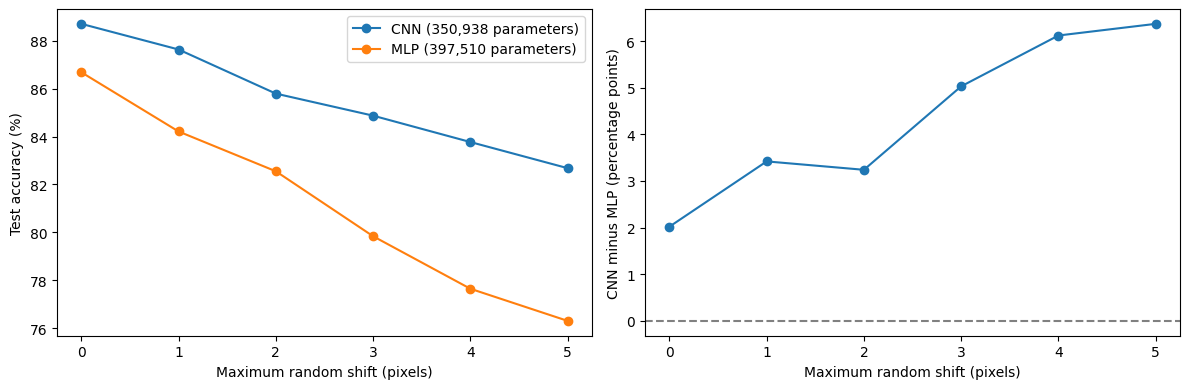

Advantage: 2.020 pp at 0 pixels → 6.370 pp at 5 pixels; change 4.350 pp.
Signed advantage ratio a5/a0 = 3.153.
Endpoint advantage increased ; inspect the curve for nonmonotonic intermediate levels.


In [7]:
def shift_images(X,max_shift,seed):
    if max_shift==0: return X.copy()
    r=np.random.RandomState(seed); m,H,W=X.shape
    P=np.pad(X,((0,0),(max_shift,max_shift),(max_shift,max_shift)))
    dy=r.randint(0,2*max_shift+1,m); dx=r.randint(0,2*max_shift+1,m)
    out=np.empty_like(X)
    for i in range(m): out[i]=P[i,dy[i]:dy[i]+H,dx[i]:dx[i]+W]
    return out
translation=[]
for shift in range(6):
    xtr=shift_images(X_train,shift,101); xte=shift_images(X_test,shift,202)
    row=dict(shift=shift)
    for family,n,factories in [('CNN',best_cnn,cnn_factories),('MLP',best_mlp,mlp_factories)]:
        if shift==0: r=results[n]
        else: _,r=run_experiment(f'translation_{shift}_{n}',factories[n],xtr,xte)
        row[family]=r['accuracy']; row[family+'_parameters']=r['parameters']
    row['advantage_pp']=row['CNN']-row['MLP']; translation.append(row)
td=pd.DataFrame(translation); display(td)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for family in ['CNN','MLP']: axs[0].plot(td['shift'],td[family],'o-',label=f'{family} ({translation[0][family+"_parameters"]:,} parameters)')
axs[0].set(xlabel='Maximum random shift (pixels)',ylabel='Test accuracy (%)'); axs[0].legend()
axs[1].plot(td['shift'],td.advantage_pp,'o-'); axs[1].axhline(0,color='gray',ls='--'); axs[1].set(xlabel='Maximum random shift (pixels)',ylabel='CNN minus MLP (percentage points)')
plt.tight_layout(); plt.show()
a0,a5=td.advantage_pp.iloc[0],td.advantage_pp.iloc[-1]
print(f'Advantage: {a0:.3f} pp at 0 pixels → {a5:.3f} pp at 5 pixels; change {a5-a0:.3f} pp.')
if abs(a0)<1e-8: print('Factor undefined because initial advantage is zero.')
else:
    print(f'Signed advantage ratio a5/a0 = {a5/a0:.3f}.')
    if a0*a5<=0: print('The advantage changes sign or reaches zero; a multiplicative growth description would be misleading.')
print('Endpoint advantage', 'increased' if a5>a0 else 'did not increase', '; inspect the curve for nonmonotonic intermediate levels.')

Convolution's local connections exploit neighboring pixels, while weight sharing lets the same detector respond at different positions. Max pooling adds tolerance within small neighborhoods; convolution alone is translation equivariant away from boundaries, and the flattened classifier still depends on position. Cropping at image boundaries can hurt both families at larger shifts. Each translation is sampled once per image, rather than regenerated each epoch, as specified by the manual.

A CNN need not win when useful relationships do not follow local spatial neighborhoods, such as a table of income, age and credit utilization with arbitrarily ordered columns. A fixed random permutation of every Fashion-MNIST image is another concrete example: an MLP can learn the fixed feature mapping, but a small CNN's locality assumption is disrupted.

## Task 5 — Learned filters, activations and confusion

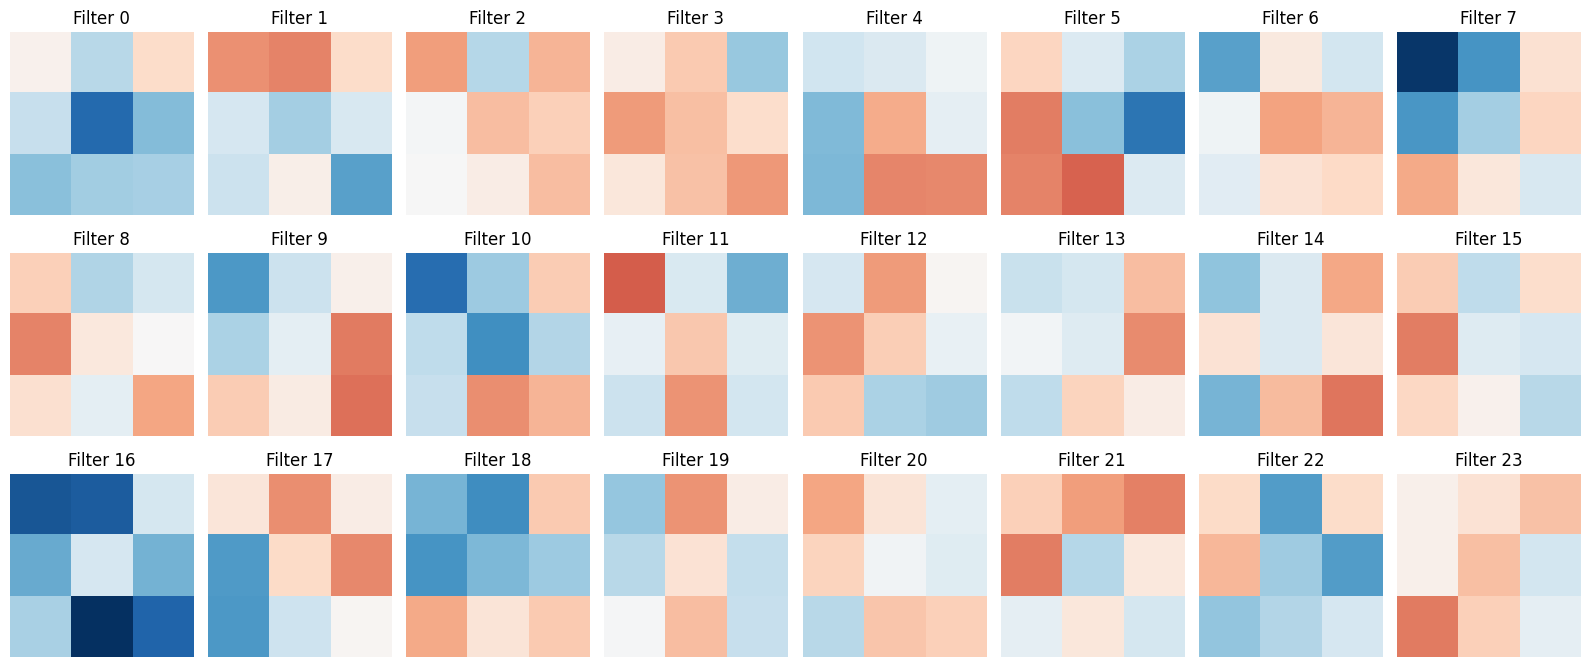

,filter,nearest_hand_kernel,absolute_correlation,sign
0,5,Sobel Gx,0.797097,opposite
1,13,Sobel Gx,0.735743,same


Least similar learned filter: 19 maximum absolute template correlation: 0.20956267072025672
Inspect these filters visually: low correlation means a resemblance claim is weak. Polarity reversal still detects the same edge orientation; learned filters may combine several patterns.


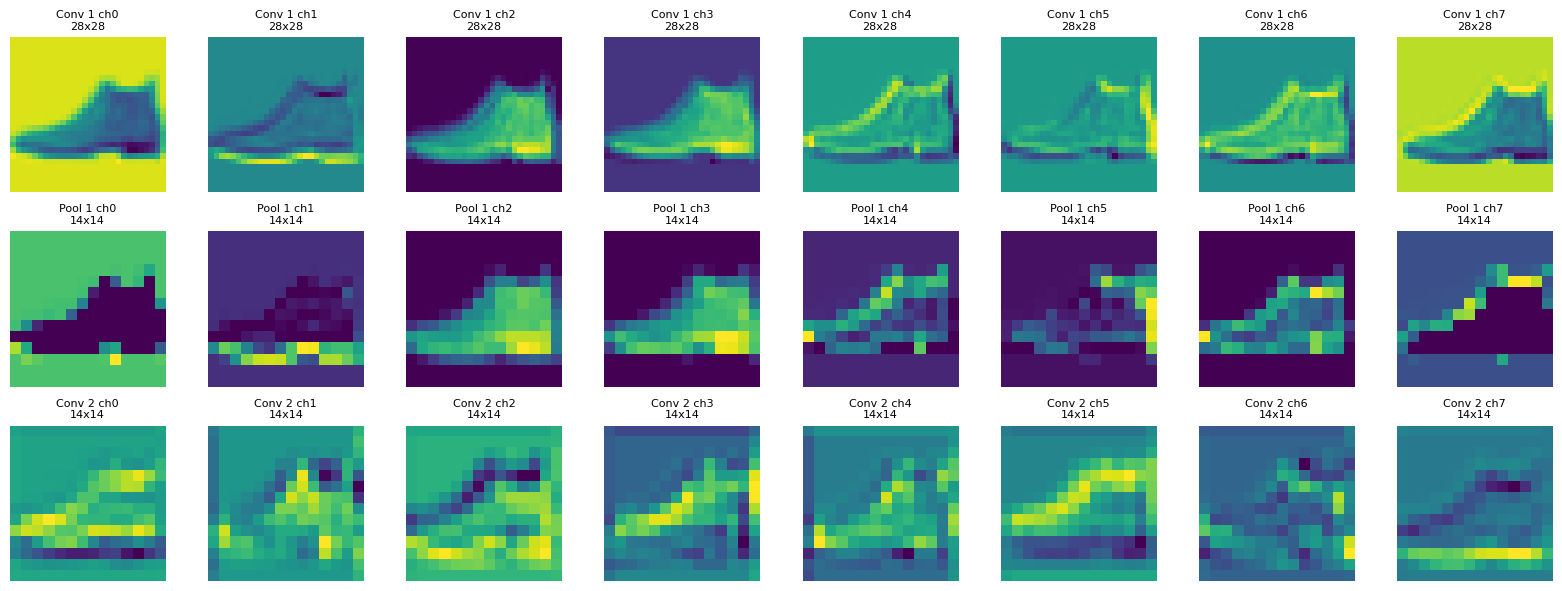

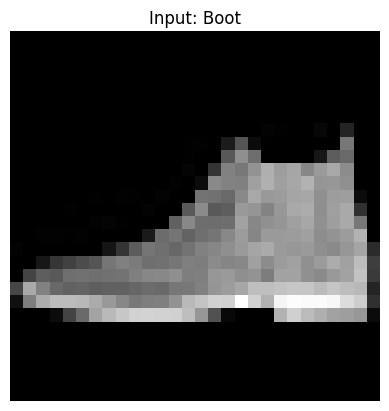

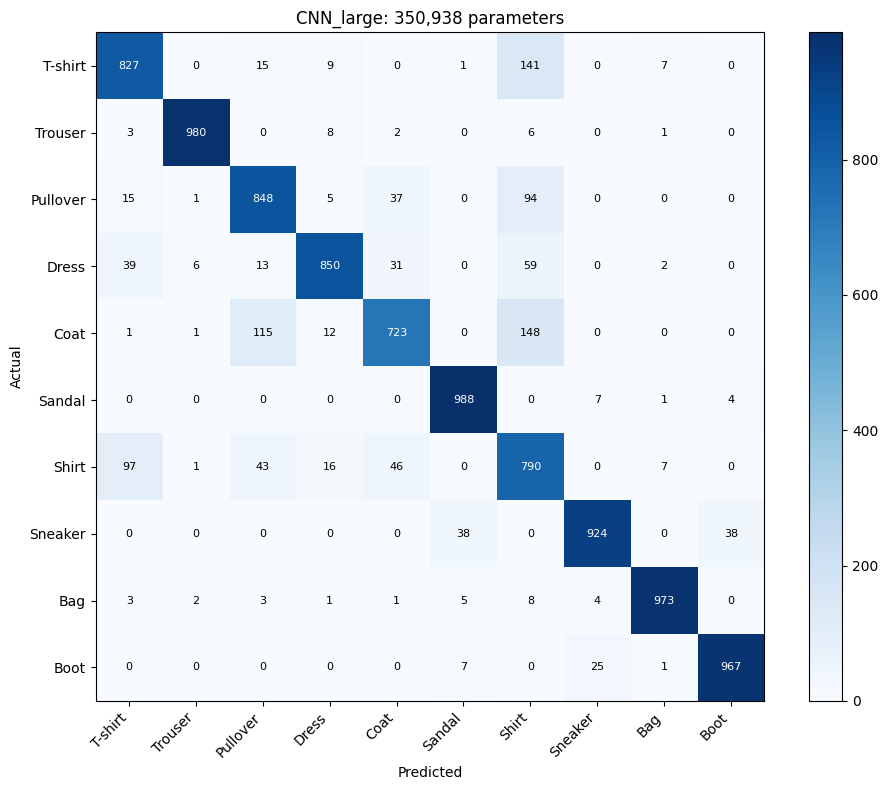

,class_name,accuracy
0,T-shirt,82.7
1,Trouser,98.0
2,Pullover,84.8
3,Dress,85.0
4,Coat,72.3
5,Sandal,98.8
6,Shirt,79.0
7,Sneaker,92.4
8,Bag,97.3
9,Boot,96.7


Most mutually confused classes: T-shirt Shirt ; combined errors: 238
Hardest class: Coat (72.30%)


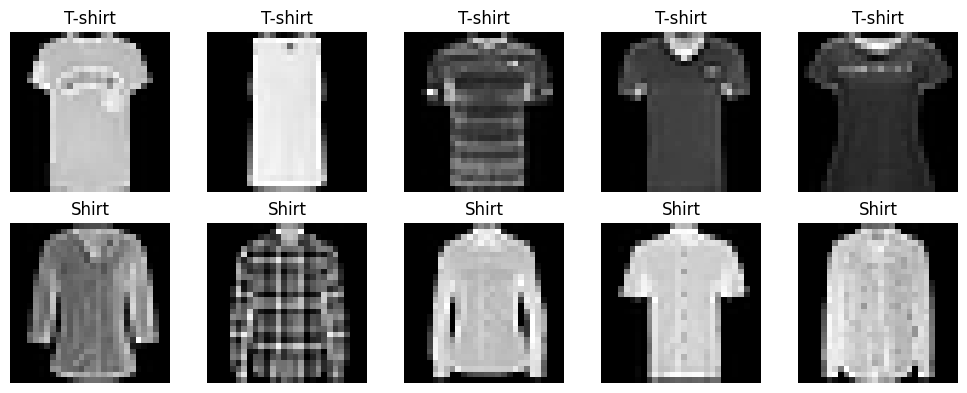

In [8]:
model=models[best_cnn]; model.eval()
filters=model.feat[0].weight.detach().cpu().numpy()[:,0]
nf=len(filters); cols=8; rows=(nf+cols-1)//cols
fig,axs=plt.subplots(rows,cols,figsize=(16,2.3*rows),squeeze=False); limit=np.max(np.abs(filters))
for j,ax in enumerate(axs.flat):
    ax.axis('off')
    if j<nf: ax.imshow(filters[j],cmap='RdBu_r',vmin=-limit,vmax=limit); ax.set_title(f'Filter {j}')
plt.tight_layout(); plt.show()
# Correlation gives reproducible candidates, not proof of semantic equivalence.
names=list(kernels); templates=np.stack([kernels[n].ravel() for n in names]); templates-=templates.mean(1,keepdims=True)
flat=filters.reshape(nf,-1); flat=flat-flat.mean(1,keepdims=True)
corr=(flat@templates.T)/np.maximum(np.linalg.norm(flat,axis=1)[:,None]*np.linalg.norm(templates,axis=1)[None,:],1e-12)
remaining=set(range(nf)); resemblance=[]
for _ in range(min(2,nf)):
    pairs=[(abs(corr[i,j]),i,j) for i in remaining for j in range(len(names))]
    score,i,j=max(pairs); remaining.remove(i)
    resemblance.append(dict(filter=i,nearest_hand_kernel=names[j],absolute_correlation=score,sign='same' if corr[i,j]>=0 else 'opposite'))
show_table(resemblance)
unlike=int(np.argmin(np.max(np.abs(corr),axis=1)))
print('Least similar learned filter:',unlike,'maximum absolute template correlation:',np.max(np.abs(corr[unlike])))
print('Inspect these filters visually: low correlation means a resemblance claim is weak. Polarity reversal still detects the same edge orientation; learned filters may combine several patterns.')
index=0; image=torch.from_numpy(X_test[index:index+1,None]).to(DEVICE)
with torch.no_grad():
    conv1=model.feat[0](image); pool1=model.feat[2](model.feat[1](conv1)); conv2=model.feat[3](pool1)
fig,axs=plt.subplots(3,8,figsize=(16,6))
for row,(name,activation) in enumerate([('Conv 1',conv1),('Pool 1',pool1),('Conv 2',conv2)]):
    arr=activation.detach().cpu().numpy()[0]
    for c in range(8):
        axs[row,c].axis('off')
        if c<len(arr): axs[row,c].imshow(arr[c],cmap='viridis'); axs[row,c].set_title(f'{name} ch{c}\n{arr.shape[1]}x{arr.shape[2]}',fontsize=8)
plt.tight_layout(); plt.show()
plt.imshow(X_test[index],cmap='gray'); plt.title('Input: '+CLASSES[Y_test[index]]); plt.axis('off'); plt.show()
_,test_loader=loaders(X_train,X_test); pred,target=evaluate(model,test_loader,True)
cm=np.zeros((10,10),dtype=int); np.add.at(cm,(target,pred),1)
fig,ax=plt.subplots(figsize=(10,8)); im=ax.imshow(cm,cmap='Blues'); fig.colorbar(im,ax=ax)
ax.set(xticks=range(10),yticks=range(10),xticklabels=CLASSES,yticklabels=CLASSES,xlabel='Predicted',ylabel='Actual',title=f'{best_cnn}: {nparams(model):,} parameters')
plt.setp(ax.get_xticklabels(),rotation=45,ha='right')
for i in range(10):
    for j in range(10): ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,color='white' if cm[i,j]>cm.max()/2 else 'black')
plt.tight_layout(); plt.show()
class_accuracy=100*cm.diagonal()/cm.sum(1); show_table([dict(class_name=n,accuracy=a) for n,a in zip(CLASSES,class_accuracy)])
hard=int(np.argmin(class_accuracy)); pairs=cm+cm.T; np.fill_diagonal(pairs,0); i,j=np.unravel_index(np.argmax(pairs),pairs.shape)
print('Most mutually confused classes:',CLASSES[i],CLASSES[j],'; combined errors:',pairs[i,j])
print('Hardest class:',CLASSES[hard],f'({class_accuracy[hard]:.2f}%)')
# Show actual images from the most confused pair to ground the explanation.
fig,axs=plt.subplots(2,5,figsize=(10,4))
for row,cls in enumerate([i,j]):
    ids=np.flatnonzero(target==cls)[:5]
    for ax,idx in zip(axs[row],ids): ax.imshow(X_test[idx],cmap='gray'); ax.set_title(CLASSES[cls]); ax.axis('off')
plt.tight_layout(); plt.show()

First-layer maps retain 28×28 spatial detail. ReLU followed by pooling keeps strong positive local responses and reduces resolution to 14×14; the second padded convolution stays at 14×14 while combining first-layer responses across channels. A feature's exact meaning requires inspection rather than assuming every filter is a Sobel detector.

Use the printed confusion pair and displayed examples to explain the observed errors: overlapping silhouettes, sleeves, necklines and texture can make clothing categories hard to distinguish at 28×28 grayscale. These ambiguities can also trouble humans, but this experiment does not measure human accuracy; it cannot establish that humans share the model's hardest class.

## Task 6 — Architecture ablation

In [ ]:
class AblationCNN(nn.Module):
    def __init__(self,depth=2,pooling=True,kernel=3):
        super().__init__(); layers=[]; ci=1; spatial=28
        for co in [8,16,32][:depth]:
            layers += [nn.Conv2d(ci,co,kernel,padding=kernel//2),nn.ReLU()]
            if pooling: layers += [nn.MaxPool2d(2)]; spatial//=2
            ci=co
        self.feat=nn.Sequential(*layers)
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(ci*spatial*spatial,32),nn.ReLU(),nn.Linear(32,10))
    def forward(self,x): return self.head(self.feat(x))
variants={'Reference':{},'Shallower':{'depth':1},'Deeper':{'depth':3},'No pooling':{'pooling':False},'5x5 kernel':{'kernel':5},'7x7 kernel':{'kernel':7}}
ablation=[]
for name,kwargs in variants.items():
    if name=='Reference': r=results['CNN_reference']
    else: _,r=run_experiment('ablation_'+name.replace(' ','_'),lambda kwargs=kwargs:AblationCNN(**kwargs))
    ablation.append(dict(variant=name,parameters=r['parameters'],accuracy=r['accuracy'],seconds=r['seconds']))
ad=pd.DataFrame(ablation); ad['accuracy_per_1k_parameters']=ad.accuracy/(ad.parameters/1000); display(ad)
fig,axs=plt.subplots(1,2,figsize=(13,5)); axs[0].bar(ad.variant,ad.accuracy); axs[0].tick_params(axis='x',rotation=40); axs[0].set_ylabel('Test accuracy (%)')
axs[1].scatter(ad.parameters,ad.accuracy)
for _,r in ad.iterrows(): axs[1].annotate(r.variant,(r.parameters,r.accuracy),fontsize=8)
axs[1].set_xscale('log'); axs[1].set(xlabel='Parameters (log scale)',ylabel='Test accuracy (%)'); plt.tight_layout(); plt.show()
for name,pooling in [('Reference',True),('No pooling',False)]:
    m=AblationCNN(pooling=pooling)
    print(name,'first dense layer:',m.head[1].in_features,'inputs;',sum(p.numel() for p in m.head[1].parameters()),'parameters; total',nparams(m))
ref=ad[ad.variant=='Reference'].iloc[0]; no=ad[ad.variant=='No pooling'].iloc[0]
print(f'No-pooling accuracy change: {no.accuracy-ref.accuracy:.3f} percentage points for {int(no.parameters-ref.parameters):,} additional parameters.')
C=64
stacked=2*(3*3*C*C+C); single=5*5*C*C+C
print(f'For equal input/intermediate/output width C={C}: two 3x3 = {stacked:,}; one 5x5 = {single:,} parameters (including bias).')
best_ratio=ad.loc[ad.accuracy_per_1k_parameters.idxmax()]
near=ad[ad.accuracy>=ad.accuracy.max()-1.0].sort_values('parameters').iloc[0]
print('Literal accuracy-per-parameter winner:',best_ratio.variant, int(best_ratio.parameters),f'parameters, {best_ratio.accuracy:.2f}% accuracy.')
print('Practical recommendation (fewest parameters within 1 pp of best accuracy):',near.variant,int(near.parameters),f'parameters, {near.accuracy:.2f}% accuracy.')
budget.to_csv(OUT/'task4_budget.csv',index=False); td.to_csv(OUT/'task4_translation.csv',index=False); ad.to_csv(OUT/'task6_ablation.csv',index=False)

ablation_Shallower: 01/12 loss=0.9122 test=79.28%
ablation_Shallower: 02/12 loss=0.5042 test=81.00%
ablation_Shallower: 03/12 loss=0.4416 test=81.89%
ablation_Shallower: 04/12 loss=0.4086 test=85.06%
ablation_Shallower: 05/12 loss=0.3812 test=85.61%
ablation_Shallower: 06/12 loss=0.3721 test=85.66%
ablation_Shallower: 07/12 loss=0.3486 test=86.48%
ablation_Shallower: 08/12 loss=0.3376 test=86.33%
ablation_Shallower: 09/12 loss=0.3218 test=86.84%
ablation_Shallower: 10/12 loss=0.3151 test=87.39%
ablation_Shallower: 11/12 loss=0.3044 test=86.58%
ablation_Shallower: 12/12 loss=0.2968 test=86.86%
ablation_Deeper: 01/12 loss=1.2362 test=69.71%
ablation_Deeper: 02/12 loss=0.7462 test=72.45%
ablation_Deeper: 03/12 loss=0.6544 test=77.53%
ablation_Deeper: 04/12 loss=0.5980 test=78.31%
ablation_Deeper: 05/12 loss=0.5460 test=80.05%
ablation_Deeper: 06/12 loss=0.5126 test=81.60%
ablation_Deeper: 07/12 loss=0.4774 test=81.22%
ablation_Deeper: 08/12 loss=0.4514 test=81.24%
ablation_Deeper: 09/12 l

The no-pooling variant expands the first dense layer from `16×7×7 → 32` to `16×28×28 → 32`: its weights grow by a factor of 16. The measured table determines whether the extra parameters improve accuracy.

Two stride-1 3×3 convolutions have a 5×5 receptive field. With constant width C, they use `18C²+2C` parameters versus `25C²+C` for one 5×5 convolution. The saving depends on channel widths; it is not universal when input, intermediate and output widths differ. VGG-style networks favor stacked small convolutions for fewer weights at comparable width and an extra nonlinearity. Receptive-field size alone does not make the two operations identical.

All ablations use the reference channels (8,16), dense width 32 and the same training settings. The deeper variant adds a third 32-channel block. Its final floor-pooled size is 3×3. Recorded time includes training plus epoch evaluations on the reported device. Accuracy-per-parameter can favor a tiny model too strongly; both a literal ratio winner and an explicit near-best-accuracy recommendation are reported.

## Viva preparation
1. Flattening preserves pixel values, but an ordinary MLP has no built-in locality or weight sharing. A fixed-pixel-permutation comparison tests this inductive-bias difference; stochastic training need not yield exactly identical finite-run accuracy.
2. `floor((28−5)/2)+1 = 12`.
3. A 7×7 kernel needs padding 3 at stride 1 to preserve size.
4. Pooling has zero learned parameters; it reduces size and adds local shift tolerance.
5. Shared and overlapping computations contribute gradients repeatedly, requiring addition.
6. A difference around 1e−2 fails verification: inspect channel order, stride, padding removal and accumulation first.
7. See Task 2 for the exact dense/convolution parameter ratio and storage cost.
8. A small centered-image gap alone does not settle the question; inspect the translation experiment with parameter counts.
9. Pooling aggregates local responses, giving limited tolerance; shared convolutions detect patterns across locations.
10. Use the actual learned-filter grid and measured template similarities, without inventing visual evidence.
11. Stacked 3×3 kernels often reduce parameters and add a nonlinearity at the same receptive-field size.
12. Removing pooling enlarges the input to the first fully connected layer.

## Save and submit
After **Run all** completes, select **File → Save**, then **File → Download → Download .ipynb** to preserve outputs. Rename it with your roll number and place it under `Lab07` in `DeepLearningLab_<YourRollNo>`. Repository upload is not performed by this notebook. To get a Google Colab link, save a copy in your Drive and use Colab's **Share → Copy link** with the access level your instructor requires.